# 02 · Análisis descriptivo y visualización

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid", context="notebook")
df = pd.read_csv(FINAL_CSV, parse_dates=["fecha"])
acc = df.drop_duplicates("num_expediente")   # nivel accidente
print(f"{len(df):,} personas implicadas | {len(acc):,} accidentes")
def save(name): plt.tight_layout(); plt.savefig(FIGURES / f"{name}.png", dpi=150); plt.show()

Matplotlib is building the font cache; this may take a moment.


271,250 personas implicadas | 115,640 accidentes


## 1. Resumen numérico

In [2]:
num = ["hora_num", "meteo_tmed", "meteo_tmin", "meteo_tmax", "meteo_prec", "meteo_velmedia", "n_implicados", "rango_termico"]
num = [c for c in num if c in df.columns]
desc = df[num].describe().T
desc["cv_%"] = (desc["std"] / desc["mean"] * 100).round(1)
desc["asimetria"] = df[num].skew()
desc

,count,mean,std,min,25%,50%,75%,max,cv_%,asimetria
hora_num,271250.0,14.024848,5.796135,0.0,10.0,15.0,19.0,23.0,41.3,-0.589415
meteo_tmed,268510.0,15.925064,7.450723,-3.4,9.8,14.6,21.6,33.4,46.8,0.352950
meteo_tmin,268510.0,10.959336,6.448476,-7.4,5.6,10.1,15.8,26.2,58.8,0.268476
meteo_tmax,268510.0,20.891115,8.701642,0.3,13.4,19.3,27.7,40.7,41.7,0.348158
meteo_prec,258455.0,1.237561,4.550551,0.0,0.0,0.0,0.0,67.7,367.7,6.681147
meteo_velmedia,203514.0,2.074678,1.014396,0.0,1.4,1.9,2.8,6.4,48.9,0.792269
n_implicados,271250.0,2.920096,1.715685,1.0,2.0,2.0,3.0,44.0,58.8,5.246513
rango_termico,268510.0,9.931779,3.534540,1.2,7.1,10.1,12.9,19.0,35.6,-0.142991


In [3]:
for c in ["gravedad", "tipo_persona", "sexo", "franja_horaria", "estacion", "intensidad_lluvia", "categoria_temp"]:
    print(f"\n{c}\n", df[c].value_counts(normalize=True, dropna=False).mul(100).round(2).to_string())


gravedad
 gravedad
desconocido    45.19
ileso          30.48
leve           19.19
moderado        3.92
grave           1.15
mortal          0.06

tipo_persona
 tipo_persona
conductor    80.65
pasajero     15.92
peaton        3.43
NaN           0.00

sexo
 sexo
hombre         60.45
mujer          28.90
desconocido    10.65

franja_horaria
 franja_horaria
tarde        50.17
mañana       21.81
noche        19.02
madrugada     8.99

estacion
 estacion
otoño        27.78
invierno     26.01
primavera    24.08
verano       22.13

intensidad_lluvia
 intensidad_lluvia
seco        75.22
debil        8.69
moderada     8.13
NaN          4.72
fuerte       3.24

categoria_temp
 categoria_temp
fresco      47.83
templado    32.80
calido      14.96
frio         3.40
NaN          1.01


## 2. Evolución temporal

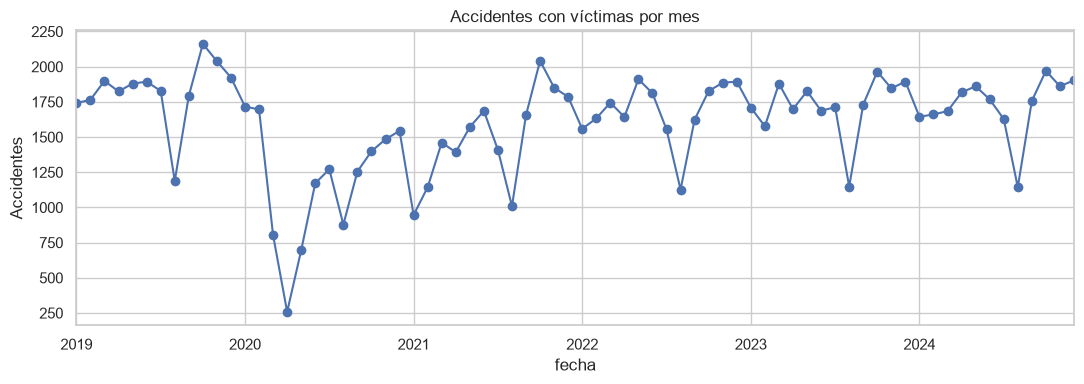

In [4]:
m = acc.set_index("fecha").resample("MS").size()
fig, ax = plt.subplots(figsize=(11, 4))
m.plot(ax=ax, marker="o"); ax.set_title("Accidentes con víctimas por mes"); ax.set_ylabel("Accidentes")
save("01_serie_mensual")

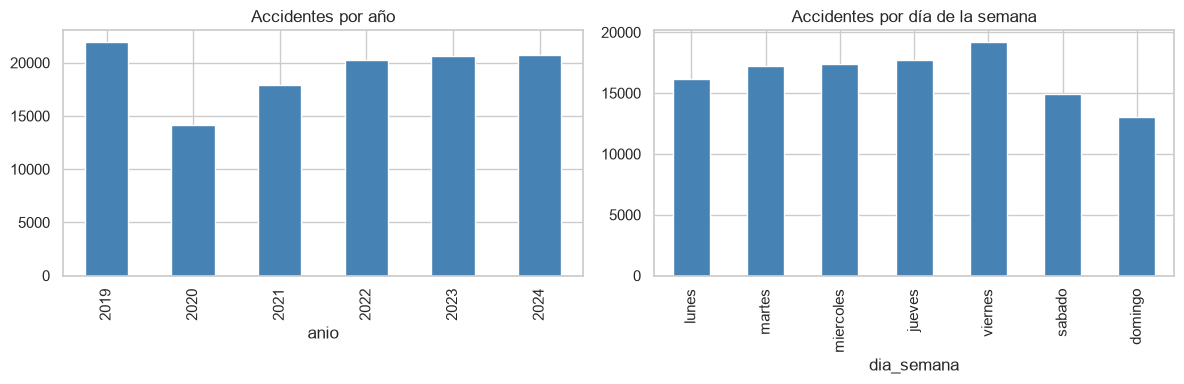

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
acc.groupby("anio").size().plot.bar(ax=axes[0], color="steelblue", title="Accidentes por año")
order = ["lunes","martes","miercoles","jueves","viernes","sabado","domingo"]
acc["dia_semana"].value_counts().reindex(order).plot.bar(ax=axes[1], color="steelblue", title="Accidentes por día de la semana")
save("02_anio_diasemana")

## 3. Hora y día de la semana (mapa de calor)

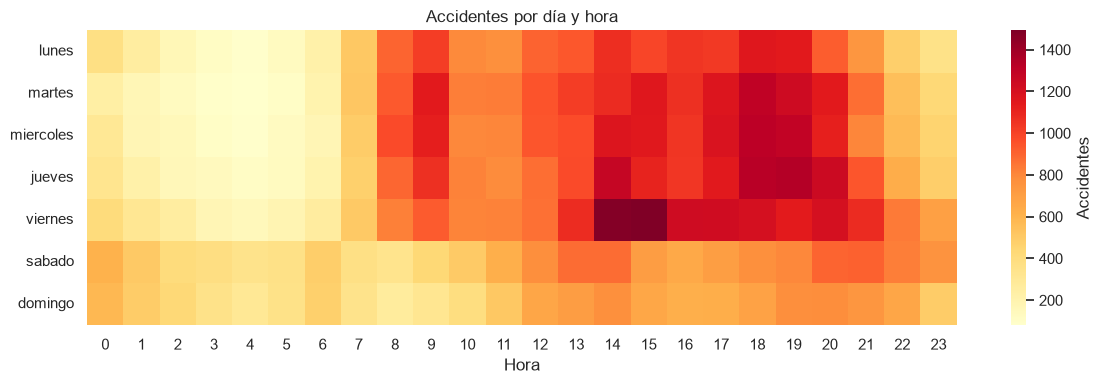

In [6]:
pt = acc.pivot_table(index="dia_semana", columns="hora_num", values="num_expediente", aggfunc="count").reindex(order)
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(pt, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Accidentes"})
ax.set_title("Accidentes por día y hora"); ax.set_xlabel("Hora"); ax.set_ylabel("")
save("03_heatmap_dia_hora")

## 4. Gravedad

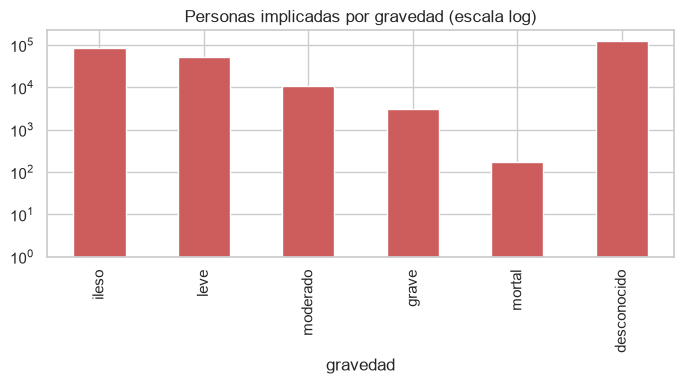

gravedad
ileso          30.48
leve           19.19
moderado        3.92
grave           1.15
mortal          0.06
desconocido    45.19
Name: count, dtype: float64


In [7]:
g = df["gravedad"].value_counts().reindex(["ileso","leve","moderado","grave","mortal","desconocido"])
fig, ax = plt.subplots(figsize=(7, 4)); g.plot.bar(ax=ax, color="indianred", log=True)
ax.set_title("Personas implicadas por gravedad (escala log)"); save("04_gravedad")
print((g / g.sum() * 100).round(2))

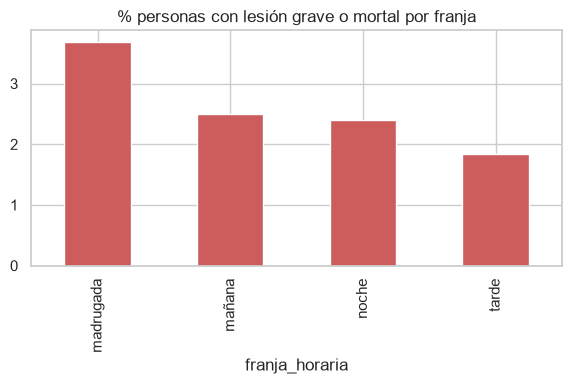

In [8]:
conocida = df[df["gravedad"] != "desconocido"]
tab = pd.crosstab(conocida["franja_horaria"], conocida["es_grave"], normalize="index") * 100
tab[1].plot.bar(figsize=(6,4), color="indianred", title="% personas con lesión grave o mortal por franja")
save("05_grave_franja")

## 5. Geografía (distritos)

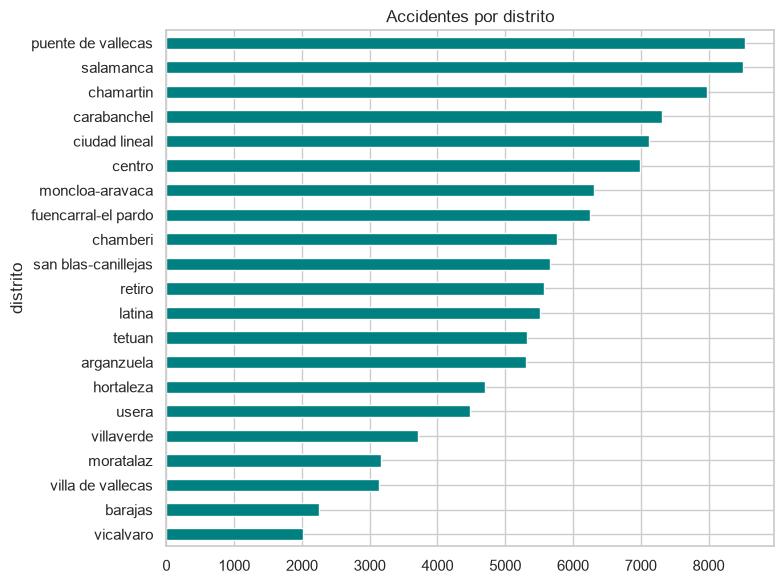

In [9]:
top = acc["distrito"].value_counts().head(21)
fig, ax = plt.subplots(figsize=(8, 6)); top.sort_values().plot.barh(ax=ax, color="teal")
ax.set_title("Accidentes por distrito"); save("06_distritos")

## 6. Meteorología

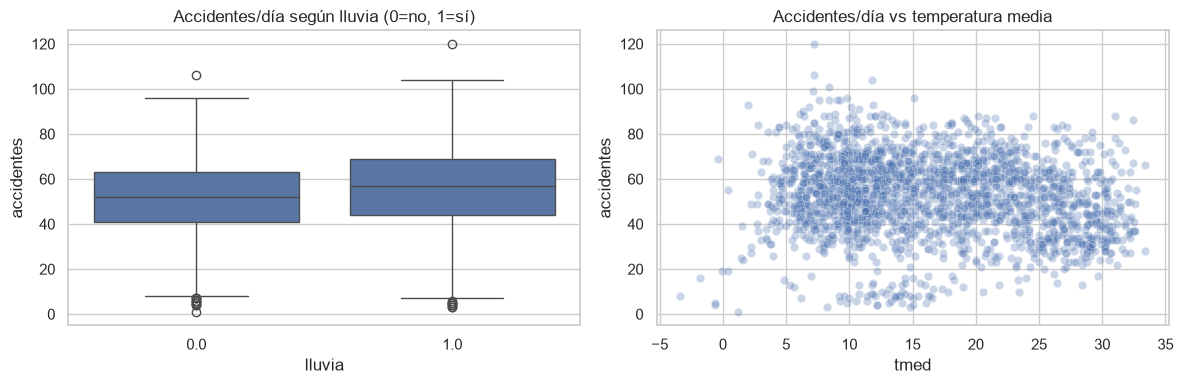

In [10]:
daily = acc.groupby("fecha").agg(accidentes=("num_expediente", "size"),
        tmed=("meteo_tmed", "first"), prec=("meteo_prec", "first"), lluvia=("lluvia", "first")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=daily.dropna(subset=["lluvia"]), x="lluvia", y="accidentes", ax=axes[0]); axes[0].set_title("Accidentes/día según lluvia (0=no, 1=sí)")
sns.scatterplot(data=daily, x="tmed", y="accidentes", alpha=.3, ax=axes[1]); axes[1].set_title("Accidentes/día vs temperatura media")
save("07_meteo")

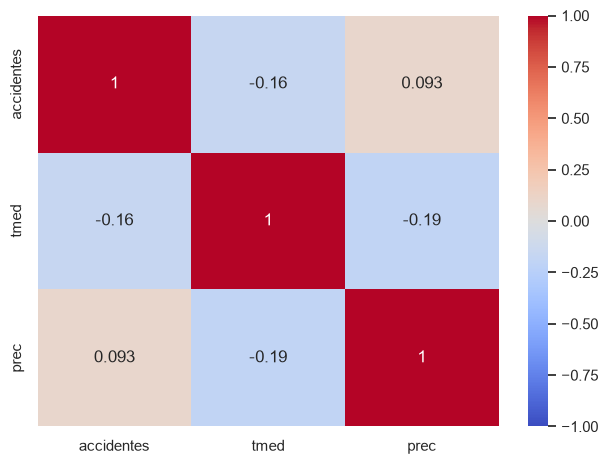

In [11]:
sns.heatmap(daily[["accidentes", "tmed", "prec"]].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
save("08_correlaciones")

## 7. Outliers
Revisar días con picos de accidentes y precipitaciones extremas (regla IQR) y decidir si son errores o eventos reales (p. ej. nevada de enero 2021, Filomena).

In [12]:
q1, q3 = daily["accidentes"].quantile([.25, .75]); iqr = q3 - q1
daily[daily["accidentes"] > q3 + 1.5*iqr].sort_values("accidentes", ascending=False).head(10)

,fecha,accidentes,tmed,prec,lluvia
94,2019-04-05,120,7.2,2.7,1.0
1067,2021-12-03,106,7.2,0.0,0.0
353,2019-12-20,104,11.8,12.8,1.0
113,2019-04-24,101,8.4,28.5,1.0
345,2019-12-12,99,7.1,1.7,1.0


## 8. Conclusiones descriptivas

1. **Volumen y tendencia.** 115.640 accidentes con víctimas (271.250 personas) entre 2019 y 2024, unos 52,8 al día. En 2020 cayeron un 35 % (14.172 frente a 21.934 en 2019) y desde 2022 se estabilizan en torno a 20.200-20.700 al año, un 6 % por debajo de 2019.
2. **Estacionalidad.** Octubre es el mes con más accidentes acumulados (11.365) y agosto el que menos (6.494).
3. **Hora.** Los picos son a las 14 h y a las 18-19 h (unos 7.700 accidentes en cada una de esas horas).
4. **Semana.** El viernes es el día con más accidentes (mediana de 65) y el domingo el que menos (42); el sábado también es bajo (48).
5. **Distritos.** Puente de Vallecas (8.539), Salamanca (8.502) y Chamartín (7.977) concentran más accidentes. El porcentaje de lesiones graves o mortales es parecido en todos (entre 1,6 % y 2,5 %).
6. **Gravedad.** El 2,2 % de las personas con lesividad conocida sufre una lesión grave o mortal (173 fallecidos a 24 h). Es el 6,2 % entre quienes van en moto, frente al 1,4 % del resto. Un 45 % de las personas no tiene lesividad registrada.